<a href="https://colab.research.google.com/github/carlossoto362/pwf_honduras_slides/blob/main/PCA_emnist.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Descargando el dataset, usaremos el test ya que es de menor tamaño

In [ ]:
import torchvision
import torchvision.transforms as transforms

# split options: 'byclass', 'bymerge', 'balanced', 'letters', 'digits', 'mnist'
#trainset = torchvision.datasets.EMNIST(
#    root="./data",
#    split="letters",
#    train=True,
#    download=True,
#    transform=transforms.ToTensor(),
#)
testset = torchvision.datasets.EMNIST(
    root="./data",
    split="letters",
    train=False,
    download=True,
    transform=transforms.ToTensor(),
)

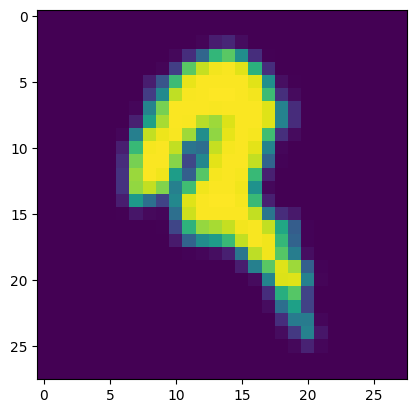

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

#datos a usar
end_index = 20000
images=testset.data[:10000].numpy()
X = images.reshape((images.shape[0],images.shape[1]*images.shape[2]))
plt.imshow(images[0])
del testset

# PCA
- Centrar la matrix X, y calcular la matris de covarianza:
$$
S = \frac{1}{n-1}X_C X_C^T
$$

In [ ]:
#S = np.cov(X)
X_mean = X.mean(axis=0)
X_centered = X - X_mean
S = (X_centered.T @ X_centered) / (X_centered.shape[0] - 1)

In [ ]:
S.shape

(784, 784)

# resolviendo el problema de eigenvalores

In [ ]:
eigenvalues = np.linalg.eigh(S)
print(eigenvalues[0].shape,eigenvalues[1].shape)

(784,) (784, 784)


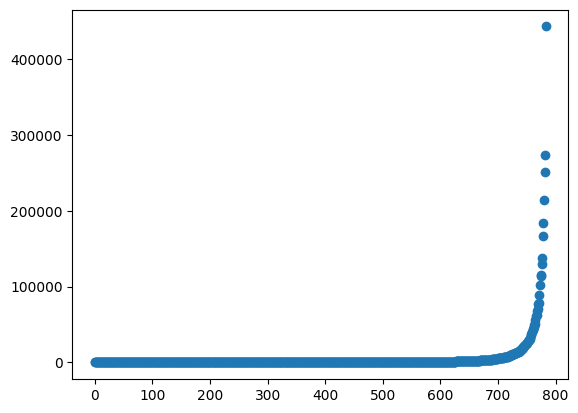

In [ ]:
plt.scatter(np.arange(784),eigenvalues[0])

In [ ]:
total_variance = 0
for i in range(eigenvalues[0].shape[0]):
  if(total_variance > 0.9):
    break
  total_variance += eigenvalues[0][-i]/eigenvalues[0].sum()
print(i)

69


In [ ]:
Projection_matrix = eigenvalues[1][:,-i:]
X_projected = X_centered @ Projection_matrix

print(X.shape,X_projected.shape)

(10000, 784) (10000, 69)


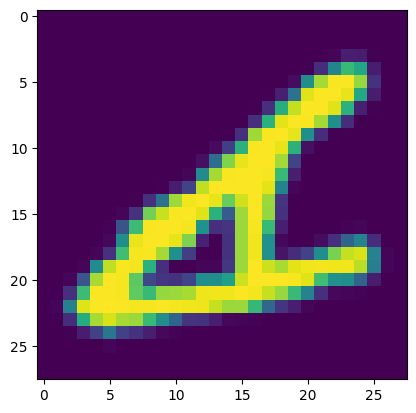

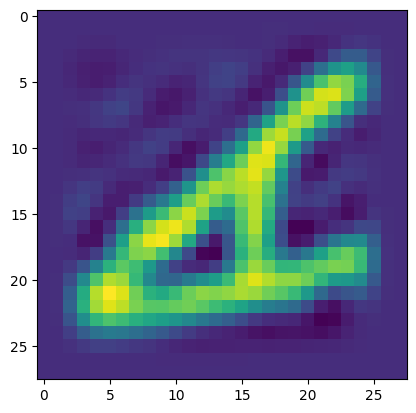

In [ ]:
X_reconstructed = X_projected @ Projection_matrix.T + X_mean
X_reconstructed = X_reconstructed.reshape(images.shape)
plt.imshow(images[1])
plt.show()
plt.imshow(X_reconstructed[1])
plt.show()